# Deliverable 2

In [21]:
# Libs for Deliverable 2
from pathlib import Path
import json
import re
import tempfile

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# All paths are built with pathlib, relative to the folder the notebook is run from
PROJECT_DIR = Path.cwd()
DATA_DIR = PROJECT_DIR / "C:/Users/tutor5923/Documents/folder_for_saving/d2_data"
LOG_DIR = DATA_DIR / "2026"
CONFIG_PATH = DATA_DIR / "store_config.json"
OUTPUT_DIR = PROJECT_DIR / "deliverables"

STATUSES = ["SUCCESS", "REFUND", "CANCELLED"]


## Task 1

### Part 1 robust file reader

In [22]:
def file_reader(file_path: str | Path) -> tuple[str, str]:
    '''
    Robust file reader that reads a text file using pathlib.
    Tries UTF-8 first and falls back to ISO-8859-1 (Latin-1), the encoding is not hard coded.
    Returns a tuple containing two strings: (file_text_content, encoding_used)
    '''
    path = Path(file_path)

    try:
        return path.read_text(encoding="utf-8"), "utf-8"
    except UnicodeDecodeError:
        return path.read_text(encoding="iso-8859-1"), "iso-8859-1"

### Part 2 regular expression

In [23]:
SALES_PATTERN = re.compile(
    r"^\[(?P<timestamp>\d{4}-\d{2}-\d{2} \d{2}:\d{2}:\d{2})\] "
    r"\[(?P<register_id>[^\]]+)\] "
    r"item=(?P<item>.+?) "
    r"price=(?P<price>\d+(?:\.\d+)?) "
    r"(?P<currency>[A-Z]{3}) "
    r"\((?P<status>SUCCESS|REFUND|CANCELLED)\)$"
)


def parse_sales_log(log_text: str) -> list[dict]:
    '''
    Parses raw log text and returns a list of dictionaries, one per valid sales line.
    Noise lines (printer, network, debug messages) do not match the pattern and are skipped.
    '''
    records = []
    for line in log_text.splitlines():
        match = SALES_PATTERN.match(line.strip())
        if match:
            record = match.groupdict()
            record["price"] = float(record["price"])
            records.append(record)

    return records

# T2 -   Recursive utility functions

In [24]:
def directory_searcher(directory_path: str | Path) -> list[Path]:
    '''
    Recursively finds all .log files in a nested directory and returns them as a list of Path objects.
    Constraint: does not use Path.glob, Path.rglob or os.walk, only Path.iterdir and recursion.
    '''
    path = Path(directory_path)

    if not path.is_dir():
        print(f"Path {path} is not a directory.")
        return []

    log_files = []
    for item in path.iterdir():
        if item.is_dir():
            log_files.extend(directory_searcher(item))
        elif item.is_file() and item.suffix == ".log":
            log_files.append(item)

    return log_files

In [25]:
for log_file in sorted(directory_searcher(LOG_DIR)):
    _, encoding = file_reader(log_file)
    print(f"{log_file.relative_to(DATA_DIR)}  ({encoding})")

Path /home/kristian/Coding/INF201/Oblig/INF201_deliverable_2/C:/Users/tutor5923/Documents/folder_for_saving/d2_data/2026 is not a directory.


### Part 2: Recursive search for active registers in `store_config.json`

The function does not assume anything about the structure of the file: a dictionary that has `"active": true` and an `"id"` is a register, and every value of a dictionary and every element of a list is searched recursively. This works for any depth and any combination of dicts and lists.

In [26]:
def get_active_registers(data) -> set[str]:
    '''
    Recursively traverses any combination of nested dicts and lists
    and returns a set of all register IDs where "active" is True.
    '''
    active_ids: set[str] = set()

    if isinstance(data, dict):
        # The dictionary itself is an active register
        if data.get("active") is True and "id" in data:
            active_ids.add(str(data["id"]))

        # Recurse into every value of the dictionary
        for value in data.values():
            active_ids |= get_active_registers(value)

    elif isinstance(data, list):
        # Recurse into every element of the list
        for item in data:
            active_ids |= get_active_registers(item)

    return active_ids


def load_active_registers_from_file(file_path: str | Path) -> set[str]:
    '''Loads store_config.json and returns the active register IDs using get_active_registers.'''
    config_data = json.loads(Path(file_path).read_text(encoding="utf-8"))
    return get_active_registers(config_data)

In [27]:
# Test on a deeper, irregular structure than the real file
nested_test = {
    "registers": [{"id": "A", "active": True}, {"id": "B", "active": False}],
    "extra": [[{"stores": [{"registers": [{"id": "C", "active": True}]}]}], {"id": "D"}],
}
print("Test structure:", sorted(get_active_registers(nested_test)))   # expected ['A', 'C']
print("store_config.json:", sorted(load_active_registers_from_file(CONFIG_PATH)))

Test structure: ['A', 'C']


FileNotFoundError: [Errno 2] No such file or directory: '/home/kristian/Coding/INF201/Oblig/INF201_deliverable_2/C:/Users/tutor5923/Documents/folder_for_saving/d2_data/store_config.json'

# T3 - Functions for cleaning and analysing datausing NumPy

### Part 1 Removing price outliers

In [ ]:
def price_fixer(data) -> np.ndarray:
    '''
    Converts input price data to a 1D NumPy float array.
    Detects hardware glitch outliers (|x - mean| > 3 * std),
    replaces them with the median of the valid prices and returns the cleaned array.
    '''
    prices = np.asarray(data, dtype=float).ravel()

    outlier_mask = np.abs(prices - prices.mean()) > 3 * prices.std()
    valid_prices = prices[~outlier_mask]

    cleaned_prices = prices.copy()
    if valid_prices.size > 0:
        cleaned_prices[outlier_mask] = np.median(valid_prices)

    return cleaned_prices

### Part 2 Refund ratio

In [ ]:
def compute_refund_ratio(sales_count: np.ndarray, refund_count: np.ndarray) -> np.ndarray:
    '''
    Computes the element-wise refund ratio: refund_count / (sales_count + 1e-6)
    '''
    sales_arr = np.asarray(sales_count, dtype=float)
    refund_arr = np.asarray(refund_count, dtype=float)

    return refund_arr / (sales_arr + 1e-6)

# T4 - Data analysis using Pandas

# Task 4 – Data analysis with pandas

### Part 1: DataFrame from the transaction dictionaries

In [ ]:
def create_dataframe_from_log_files(data: list[dict]) -> pd.DataFrame:
    '''
    Creates a pandas DataFrame from the transaction dictionaries,
    converts timestamp to datetime, sets it as the index and sorts chronologically.
    '''
    df = pd.DataFrame(data)
    df["timestamp"] = pd.to_datetime(df["timestamp"], format="%Y-%m-%d %H:%M:%S")
    return df.set_index("timestamp").sort_index()

### Part 2: Hourly revenue per item

In [ ]:
def data_grouper(df: pd.DataFrame) -> pd.DataFrame:
    '''
    Groups the transactions by item, resamples them into 1-hour windows
    and calculates the total price (sum) per item per hour.
    '''
    return df.groupby("item").resample("1h")[["price"]].sum()

### Part 3: Pivot table of revenue per item and status

In [ ]:
def create_pivot(df: pd.DataFrame) -> pd.DataFrame:
    '''
    Creates a pivot table displaying total transaction revenue
    grouped by item across the status categories (SUCCESS, REFUND, CANCELLED).
    '''
    pivot_table = df.pivot_table(index="item", columns="status", values="price", aggfunc="sum", fill_value=0)
    # Make sure all three status columns exist and are in a fixed order
    return pivot_table.reindex(columns=STATUSES, fill_value=0)

### Part 4: Refund ratio per item

**Definition of "sales count":** a log line with status `REFUND` or `CANCELLED` is not a completed sale, so we use the number of `SUCCESS` transactions as the sales count. Counting all transactions instead would make the denominator include the refunds themselves. All counts are computed in one `groupby`, and `compute_refund_ratio` is called **once** on whole arrays.

In [ ]:
def calculate_refund_ratio(df: pd.DataFrame) -> pd.DataFrame:
    '''
    Calculates the refund ratio per item using compute_refund_ratio from task 3.
    Sales count = number of SUCCESS transactions, refund count = number of REFUND transactions.
    '''
    counts = df.groupby("item")["status"].agg(
        sales_count=lambda s: (s == "SUCCESS").sum(),
        refund_count=lambda s: (s == "REFUND").sum(),
    )
    counts["refund_ratio"] = compute_refund_ratio(counts["sales_count"].to_numpy(), counts["refund_count"].to_numpy())
    return counts

### Part 3: Pivot table of revenue per item and status

# T5 -  Create full workflow

In [28]:
log_files = sorted(directory_searcher(LOG_DIR))
active_registers = load_active_registers_from_file(CONFIG_PATH)

print(f"Found {len(log_files)} log files")
print(f"Active registers: {sorted(active_registers)}")

Path /home/kristian/Coding/INF201/Oblig/INF201_deliverable_2/C:/Users/tutor5923/Documents/folder_for_saving/d2_data/2026 is not a directory.


FileNotFoundError: [Errno 2] No such file or directory: '/home/kristian/Coding/INF201/Oblig/INF201_deliverable_2/C:/Users/tutor5923/Documents/folder_for_saving/d2_data/store_config.json'

In [15]:
all_records = []
noise_lines = 0
for log_file in log_files:
    content, encoding = file_reader(log_file)
    records = parse_sales_log(content)
    noise_lines += len(content.splitlines()) - len(records)
    all_records.extend(records)

active_records = [r for r in all_records if r["register_id"] in active_registers]

print(f"Valid transactions: {len(all_records)}, ignored noise lines: {noise_lines}")
print(f"Transactions from inactive registers removed: {len(all_records) - len(active_records)}")

Valid transactions: 0, ignored noise lines: 0
Transactions from inactive registers removed: 0


In [16]:
df = create_dataframe_from_log_files(active_records)
df.head()

KeyError: 'timestamp'

In [17]:
raw_prices = df["price"].to_numpy()
df["price"] = price_fixer(raw_prices)

replaced = raw_prices != df["price"].to_numpy()
print(f"Mean {raw_prices.mean():.2f}, std {raw_prices.std():.2f} -> outlier if price > {raw_prices.mean() + 3 * raw_prices.std():.2f}")
print(f"Replaced {replaced.sum()} outliers with raw values {np.unique(raw_prices[replaced])} by the median {df['price'][replaced].iloc[0]:.2f}")
print(f"Price range after cleaning: {df['price'].min():.2f} - {df['price'].max():.2f}")

NameError: name 'df' is not defined

NameError: name 'raw_prices' is not defined

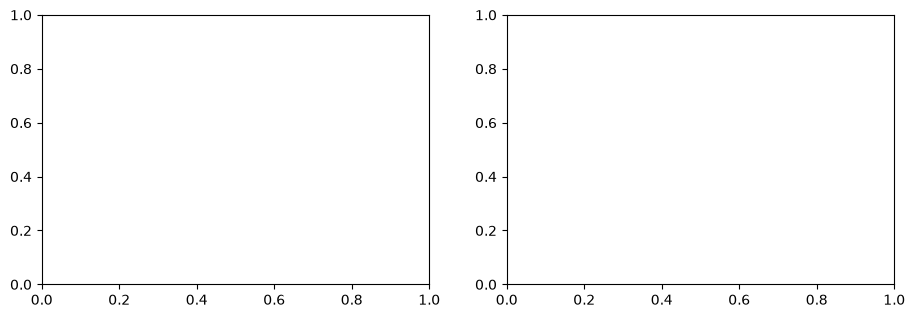

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].hist(raw_prices, bins=60)
axes[0].set(title="Prices before outlier cleaning", xlabel="price", ylabel="transactions", yscale="log")
axes[1].hist(df["price"], bins=30)
axes[1].set(title="Prices after outlier cleaning", xlabel="price", ylabel="transactions")
plt.tight_layout()
plt.show()